# Global Solution – MLAM (CitizenTech)
**Qualidade de vida das comunidades: o que se associa à expectativa de vida?**

Base: *Global Country Information Dataset 2023* (Kaggle) – 195 países, indicadores reais compilados de múltiplas fontes públicas (autor: Nidula Elgiriyewithana).

Este notebook cobre os itens 02 a 06 do enunciado (distribuição normal, testes de hipóteses, análise bivariada, regressão linear múltipla e regressão logística). Os resultados são salvos em `resultados/resultados.json` e as figuras em `figuras/`, e alimentam o relatório em PDF.

In [1]:
import sys, os, json, warnings
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})

try:
    AQUI = os.path.dirname(os.path.abspath(__file__))
except NameError:
    AQUI = os.getcwd()
BASE = os.path.abspath(os.path.join(AQUI, ".."))
ARQ_DADOS = os.path.join(BASE, "dados", "world-data-2023.csv")
DIR_FIG = os.path.join(BASE, "figuras")
DIR_RES = os.path.join(BASE, "resultados")
os.makedirs(DIR_FIG, exist_ok=True); os.makedirs(DIR_RES, exist_ok=True)

RES = {}   # dicionário com todos os resultados (vai para o relatório)

def salvar(nome):
    plt.tight_layout()
    plt.savefig(os.path.join(DIR_FIG, nome), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

def forca(r):
    a = abs(r)
    if a < 0.3: f = "fraca"
    elif a < 0.5: f = "moderada"
    elif a < 0.7: f = "forte"
    else: f = "muito forte"
    return f + (" e positiva" if r > 0 else " e negativa")

## 1. Base de dados: leitura, limpeza e variáveis
Fonte: Kaggle – *Global Country Information Dataset 2023*. As colunas numéricas vêm como texto (`58.10%`, `"652,230"`), então removemos `%`, `$` e vírgulas e convertemos para número. Também criamos `urbanizacao` (% da população em áreas urbanas = população urbana / população × 100), variável ligada ao tema de cidades do CitizenTech.

In [2]:
bruto = pd.read_csv(ARQ_DADOS)
bruto.columns = [c.replace("\n", " ").strip() for c in bruto.columns]

def para_numero(s):
    return pd.to_numeric(s.astype(str).str.replace(r"[\$,%]", "", regex=True).str.strip(), errors="coerce")

df = pd.DataFrame({"pais": bruto["Country"]})
df["expectativa_vida"] = para_numero(bruto["Life expectancy"])                       # anos
df["medicos_mil"]      = para_numero(bruto["Physicians per thousand"])               # médicos por mil hab.
df["ensino_superior"]  = para_numero(bruto["Gross tertiary education enrollment (%)"])  # % matrícula bruta
df["fertilidade"]      = para_numero(bruto["Fertility Rate"])                         # filhos por mulher
df["populacao"]        = para_numero(bruto["Population"])
df["pop_urbana"]       = para_numero(bruto["Urban_population"])
df["urbanizacao"]      = 100 * df["pop_urbana"] / df["populacao"]                     # % urbana
df.to_csv(os.path.join(BASE, "dados", "base_tratada.csv"), index=False)

usadas = ["expectativa_vida", "medicos_mil", "ensino_superior", "fertilidade", "urbanizacao"]
print("Países na base:", len(df))
print("\nValores ausentes por variável usada:")
print(df[usadas].isna().sum().to_string())
print("\nEstatísticas descritivas:")
desc = df[usadas].describe().round(2)
print(desc.to_string())
print("\nUrbanização máxima (deve ser <= 100):", round(df["urbanizacao"].max(), 1))
completos = df.dropna(subset=usadas)
print("Países com as 5 variáveis completas:", len(completos))
RES["base"] = {"n_total": int(len(df)), "n_completos": int(len(completos)),
               "ausentes": {k: int(v) for k, v in df[usadas].isna().sum().items()},
               "descritivas": desc.to_dict()}

Países na base: 195

Valores ausentes por variável usada:
expectativa_vida     8
medicos_mil          7
ensino_superior     12
fertilidade          7
urbanizacao          5

Estatísticas descritivas:
       expectativa_vida  medicos_mil  ensino_superior  fertilidade  urbanizacao
count            187.00       188.00           183.00       188.00       190.00
mean              72.28         1.84            37.96         2.70        58.77
std                7.48         1.68            29.26         1.28        23.33
min               52.80         0.01             0.80         0.98        11.43
25%               67.00         0.33            12.15         1.70        41.02
50%               73.20         1.46            31.20         2.24        59.54
75%               77.50         2.94            63.15         3.60        77.94
max               85.40         8.42           136.60         6.91       100.00

Urbanização máxima (deve ser <= 100): 100.0
Países com as 5 variáveis completas

## 2. Distribuição Normal de Probabilidade (1,0 ponto)
Variável escolhida: **expectativa de vida (anos)**. Assumindo distribuição normal com média e desvio padrão amostral da variável:

a) P(X < média)  b) P(X > mediana)

Critério de classificação do evento: 0 a 25% improvável; 25% a menos de 50% pouco provável; exatamente 50% equiprovável; acima de 50% até 75% provável; acima de 75% muito provável.

n = 187 | média = 72.280 | mediana = 73.200 | desvio padrão amostral = 7.484
Shapiro-Wilk: W = 0.9631, p-valor = 8.029e-05 (a normalidade é uma suposição do enunciado)

a) P(X < média = 72.28) = 0.5000 (50.00%) -> evento equiprovável (chance de 50%)
b) P(X > mediana = 73.20) = 0.4511 (45.11%) -> evento pouco provável (possível, mas com chance menor que 50%)

Interpretação: sob a normal, metade dos países fica abaixo da média por simetria. Como a mediana dos dados é maior que a média (distribuição assimétrica à esquerda), a probabilidade de superar a mediana fica abaixo de 50% no modelo normal.


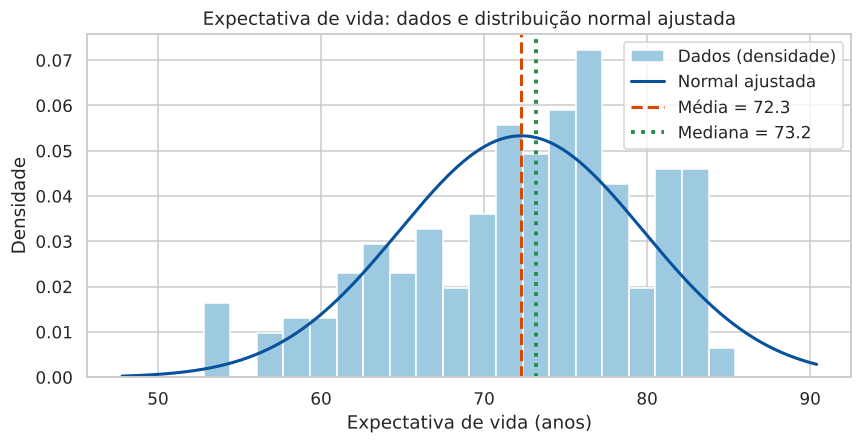

In [3]:
x = df["expectativa_vida"].dropna()
mu, sigma, mediana = x.mean(), x.std(ddof=1), x.median()
print(f"n = {len(x)} | média = {mu:.3f} | mediana = {mediana:.3f} | desvio padrão amostral = {sigma:.3f}")
sw = stats.shapiro(x)
print(f"Shapiro-Wilk: W = {sw.statistic:.4f}, p-valor = {sw.pvalue:.4g} (a normalidade é uma suposição do enunciado)")

def classificar(p):
    if np.isclose(p, 0.5, atol=1e-6): return "equiprovável (chance de 50%)"
    if p < 0.25: return "improvável"
    if p < 0.5:  return "pouco provável (possível, mas com chance menor que 50%)"
    if p <= 0.75: return "provável"
    return "muito provável"

p_a = stats.norm.cdf(mu, loc=mu, scale=sigma)
p_b = stats.norm.sf(mediana, loc=mu, scale=sigma)
print(f"\na) P(X < média = {mu:.2f}) = {p_a:.4f} ({p_a*100:.2f}%) -> evento {classificar(p_a)}")
print(f"b) P(X > mediana = {mediana:.2f}) = {p_b:.4f} ({p_b*100:.2f}%) -> evento {classificar(p_b)}")
print("\nInterpretação: sob a normal, metade dos países fica abaixo da média por simetria. "
      "Como a mediana dos dados é maior que a média (distribuição assimétrica à esquerda), "
      "a probabilidade de superar a mediana fica abaixo de 50% no modelo normal.")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(x, bins=20, density=True, color="#9ecae1", edgecolor="white", label="Dados (densidade)")
xs = np.linspace(x.min() - 5, x.max() + 5, 400)
ax.plot(xs, stats.norm.pdf(xs, mu, sigma), color="#08519c", lw=2, label="Normal ajustada")
ax.axvline(mu, color="#d94801", ls="--", lw=2, label=f"Média = {mu:.1f}")
ax.axvline(mediana, color="#238b45", ls=":", lw=2.5, label=f"Mediana = {mediana:.1f}")
ax.set_title("Expectativa de vida: dados e distribuição normal ajustada")
ax.set_xlabel("Expectativa de vida (anos)"); ax.set_ylabel("Densidade"); ax.legend()
salvar("fig02_normal.png")

RES["q02"] = {"n": int(len(x)), "media": mu, "mediana": mediana, "desvio": sigma,
              "shapiro_W": sw.statistic, "shapiro_p": sw.pvalue,
              "p_a": p_a, "classe_a": classificar(p_a), "p_b": p_b, "classe_b": classificar(p_b)}

## 3. Testes de hipóteses para a média (1,0 ponto)
Variável: expectativa de vida. Média populacional de referência (μ₀) e desvio padrão de referência (σ) = média e desvio padrão populacional (ddof = 0) dos dados. Teste Z com σ conhecido; as amostras são sorteadas sem reposição (semente fixa, reprodutível).

a) H₀: μ = μ₀ contra H₁: μ < μ₀, α = 6%, n = 20.
b) H₀: μ = μ₀ contra H₁: μ > μ₀, α = 9%, n = 25.

μ0 (referência) = 72.280 | σ (referência, populacional) = 7.464

a) H0: μ = μ0 | H1: μ < μ0 | α = 6% | n = 20
   média amostral = 71.690 | z calculado = -0.3533 | z crítico = -1.5548 | p-valor = 0.3619
   Decisão: NÃO REJEITA H0 (sem evidência suficiente de diferença em relação a μ0).

b) H0: μ = μ0 | H1: μ > μ0 | α = 9% | n = 25
   média amostral = 74.284 | z calculado = 1.3427 | z crítico = 1.3408 | p-valor = 0.0897
   Decisão: REJEITA H0 (evidência de que a média difere de μ0 no sentido de H1).


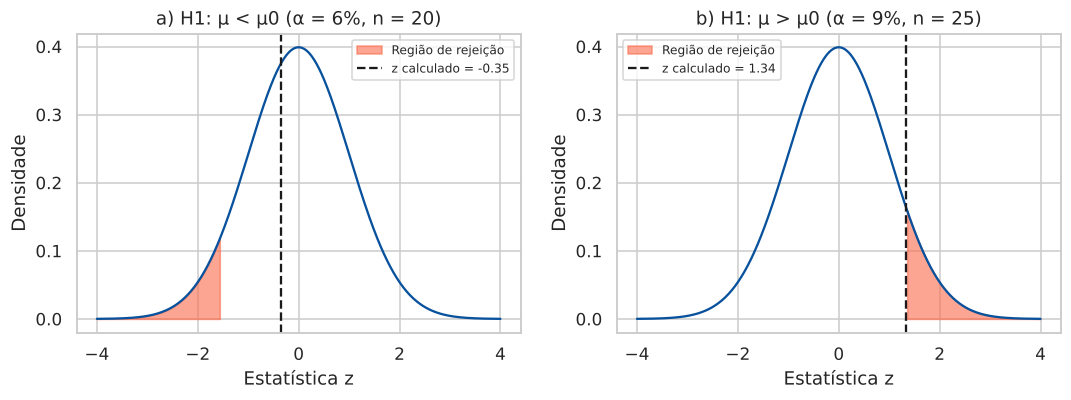


Verificação (10.000 amostras): rejeição em a) = 0.056 (α = 0,06) | em b) = 0.073 (α = 0,09)
Como as amostras vêm da própria base que define μ0, H0 é verdadeira por construção: rejeitá-la seria erro tipo I.


In [4]:
mu0 = x.mean()
sigma_pop = x.std(ddof=0)
print(f"μ0 (referência) = {mu0:.3f} | σ (referência, populacional) = {sigma_pop:.3f}")

def teste_z(amostra, alpha, cauda):
    n = len(amostra); xbar = float(np.mean(amostra))
    z = (xbar - mu0) / (sigma_pop / np.sqrt(n))
    if cauda == "menor":
        zc = stats.norm.ppf(alpha); p = stats.norm.cdf(z); rej = bool(z < zc)
    else:
        zc = stats.norm.ppf(1 - alpha); p = stats.norm.sf(z); rej = bool(z > zc)
    return {"n": n, "alpha": alpha, "cauda": cauda, "xbar": xbar, "z": float(z),
            "z_crit": float(zc), "p_valor": float(p), "rejeita": rej}

rng = np.random.default_rng(2026)
amostra_a = rng.choice(x.values, size=20, replace=False)
amostra_b = rng.choice(x.values, size=25, replace=False)
ta = teste_z(amostra_a, 0.06, "menor")
tb = teste_z(amostra_b, 0.09, "maior")

for nome, t, h1 in [("a)", ta, "μ < μ0"), ("b)", tb, "μ > μ0")]:
    print(f"\n{nome} H0: μ = μ0 | H1: {h1} | α = {t['alpha']*100:.0f}% | n = {t['n']}")
    print(f"   média amostral = {t['xbar']:.3f} | z calculado = {t['z']:.4f} | z crítico = {t['z_crit']:.4f} | p-valor = {t['p_valor']:.4f}")
    if t["rejeita"]:
        print("   Decisão: REJEITA H0 (evidência de que a média difere de μ0 no sentido de H1).")
    else:
        print("   Decisão: NÃO REJEITA H0 (sem evidência suficiente de diferença em relação a μ0).")

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, t, tit in [(axs[0], ta, "a) H1: μ < μ0 (α = 6%, n = 20)"), (axs[1], tb, "b) H1: μ > μ0 (α = 9%, n = 25)")]:
    zs = np.linspace(-4, 4, 500)
    ax.plot(zs, stats.norm.pdf(zs), color="#08519c")
    m = zs <= t["z_crit"] if t["cauda"] == "menor" else zs >= t["z_crit"]
    ax.fill_between(zs[m], stats.norm.pdf(zs[m]), color="#fb6a4a", alpha=0.6, label="Região de rejeição")
    ax.axvline(t["z"], color="k", ls="--", label=f"z calculado = {t['z']:.2f}")
    ax.set_title(tit); ax.set_xlabel("Estatística z"); ax.set_ylabel("Densidade"); ax.legend(fontsize=8)
salvar("fig03_testes.png")

# Verificação extra: taxa de rejeição em 10.000 amostras (deve ficar perto de α, pois H0 é verdadeira por construção)
sim = np.random.default_rng(1)
def taxa(n, alpha, cauda, reps=10000):
    return sum(teste_z(sim.choice(x.values, n, replace=False), alpha, cauda)["rejeita"] for _ in range(reps)) / reps
taxa_a, taxa_b = taxa(20, 0.06, "menor"), taxa(25, 0.09, "maior")
print(f"\nVerificação (10.000 amostras): rejeição em a) = {taxa_a:.3f} (α = 0,06) | em b) = {taxa_b:.3f} (α = 0,09)")
print("Como as amostras vêm da própria base que define μ0, H0 é verdadeira por construção: rejeitá-la seria erro tipo I.")
RES["q03"] = {"mu0": mu0, "sigma": sigma_pop, "a": ta, "b": tb, "taxa_a": taxa_a, "taxa_b": taxa_b}

## 4. Análise bivariada (2,0 pontos)
Variáveis: **X = médicos por mil habitantes** e **Y = expectativa de vida (anos)**. A oferta de médicos é uma alavanca concreta de política pública.

Observações (países com as duas variáveis): 185


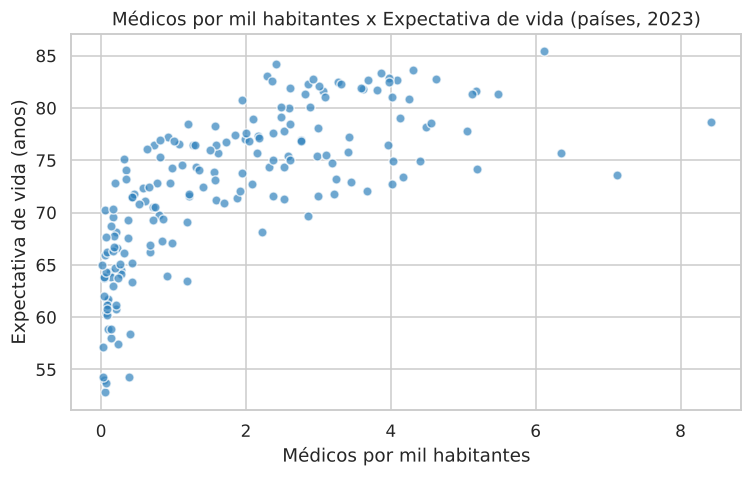

b) Covariância = 8.6317 | Correlação de Pearson r = 0.7037 (p-valor = 5.65e-29) -> relação muito forte e positiva


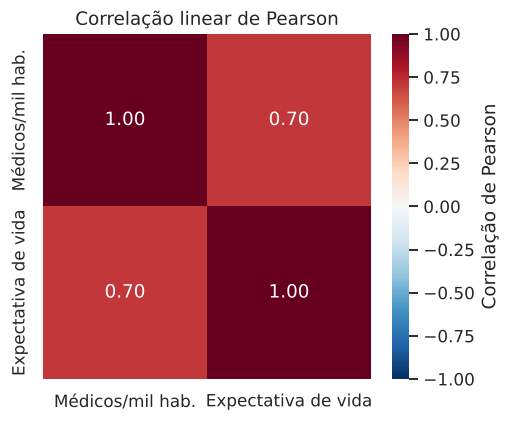

d) Equação: Expectativa de vida = 66.604 + 3.145 × Médicos por mil hab.


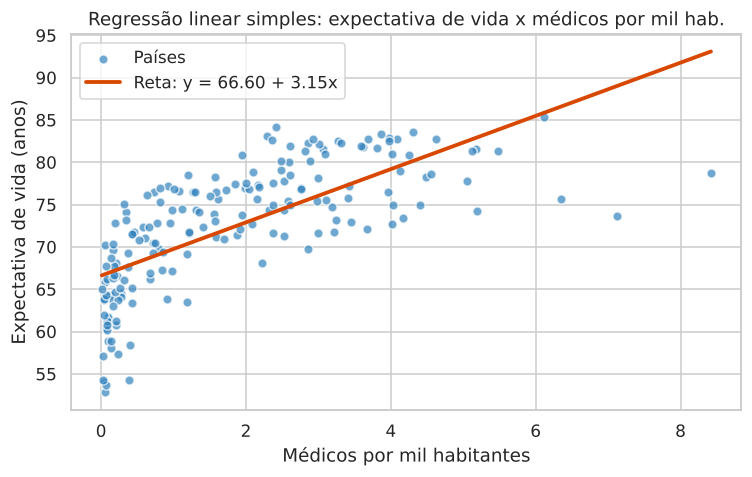

e) R² = 0.4953 | R² ajustado = 0.4925 | F(1, 183) = 179.56 | p-valor (F) = 5.65e-29
   Coeficiente de X: erro-padrão = 0.2347, t = 13.40, p-valor = 5.65e-29
   Interpretação: o modelo é estatisticamente significativo (p < 0,05) e explica 49.5% da variação da expectativa de vida.


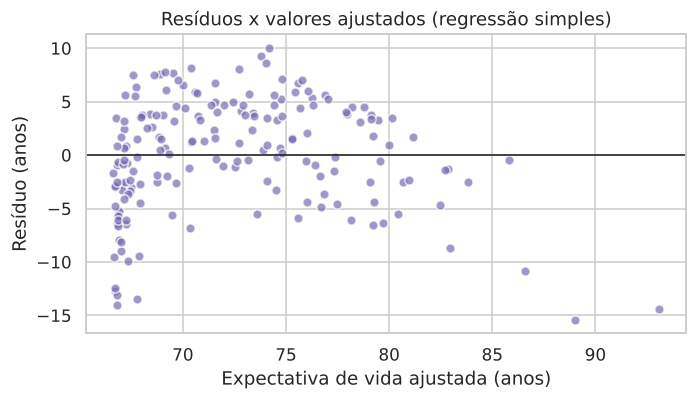

f) Previsão para 2.5 médicos por mil hab.: 74.47 anos (intervalo de predição de 95%: 64.0 a 84.9)


In [5]:
def ols(X, y):
    X = np.asarray(X, float); y = np.asarray(y, float)
    if X.ndim == 1: X = X.reshape(-1, 1)
    n = len(y); Xc = np.column_stack([np.ones(n), X]); k = Xc.shape[1] - 1
    XtXi = np.linalg.inv(Xc.T @ Xc)
    b = XtXi @ Xc.T @ y
    yhat = Xc @ b; res = y - yhat
    sse = float(res @ res); sst = float(((y - y.mean()) ** 2).sum()); ssr = sst - sse
    r2 = ssr / sst; r2a = 1 - (1 - r2) * (n - 1) / (n - k - 1)
    s2 = sse / (n - k - 1); se = np.sqrt(np.diag(XtXi) * s2)
    t = b / se; p = 2 * stats.t.sf(np.abs(t), n - k - 1)
    F = (ssr / k) / s2; pF = stats.f.sf(F, k, n - k - 1)
    return {"b": b, "se": se, "t": t, "p": p, "r2": r2, "r2a": r2a, "F": F, "pF": pF,
            "n": n, "k": k, "s2": s2, "XtXi": XtXi, "yhat": yhat, "res": res}

d4 = df[["pais", "expectativa_vida", "medicos_mil"]].dropna()
X4 = d4["medicos_mil"].values; Y4 = d4["expectativa_vida"].values
print(f"Observações (países com as duas variáveis): {len(d4)}")

# a) dispersão
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(X4, Y4, alpha=0.7, color="#3182bd", edgecolor="white")
ax.set_title("Médicos por mil habitantes x Expectativa de vida (países, 2023)")
ax.set_xlabel("Médicos por mil habitantes"); ax.set_ylabel("Expectativa de vida (anos)")
salvar("fig04a_dispersao.png")

# b) covariância e correlação
cov4 = float(np.cov(X4, Y4, ddof=1)[0, 1])
r4, pr4 = stats.pearsonr(X4, Y4)
print(f"b) Covariância = {cov4:.4f} | Correlação de Pearson r = {r4:.4f} (p-valor = {pr4:.3g}) -> relação {forca(r4)}")

# c) gráfico da correlação
cm = pd.DataFrame({"Médicos/mil hab.": X4, "Expectativa de vida": Y4}).corr()
fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Correlação de Pearson"})
ax.set_title("Correlação linear de Pearson")
salvar("fig04c_correlacao.png")

# d) reta e equação
m4 = ols(X4, Y4)
b0, b1 = m4["b"]
print(f"d) Equação: Expectativa de vida = {b0:.3f} + {b1:.3f} × Médicos por mil hab.")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(X4, Y4, alpha=0.7, color="#3182bd", edgecolor="white", label="Países")
xl = np.linspace(X4.min(), X4.max(), 100)
ax.plot(xl, b0 + b1 * xl, color="#d94801", lw=2.5, label=f"Reta: y = {b0:.2f} + {b1:.2f}x")
ax.set_title("Regressão linear simples: expectativa de vida x médicos por mil hab.")
ax.set_xlabel("Médicos por mil habitantes"); ax.set_ylabel("Expectativa de vida (anos)"); ax.legend()
salvar("fig04d_reta.png")

# e) adequação
print(f"e) R² = {m4['r2']:.4f} | R² ajustado = {m4['r2a']:.4f} | F({m4['k']}, {m4['n']-m4['k']-1}) = {m4['F']:.2f} | p-valor (F) = {m4['pF']:.3g}")
print(f"   Coeficiente de X: erro-padrão = {m4['se'][1]:.4f}, t = {m4['t'][1]:.2f}, p-valor = {m4['p'][1]:.3g}")
print(f"   Interpretação: o modelo é estatisticamente significativo (p < 0,05) e explica {m4['r2']*100:.1f}% da variação da expectativa de vida.")

# resíduos (diagnóstico extra)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.scatter(m4["yhat"], m4["res"], alpha=0.7, color="#756bb1", edgecolor="white")
ax.axhline(0, color="k", lw=1)
ax.set_title("Resíduos x valores ajustados (regressão simples)")
ax.set_xlabel("Expectativa de vida ajustada (anos)"); ax.set_ylabel("Resíduo (anos)")
salvar("fig04e_residuos.png")

# f) previsão com intervalo de predição de 95%
x0 = 2.5
v0 = np.array([1.0, x0])
pred = float(v0 @ m4["b"])
se_pred = np.sqrt(m4["s2"] * (1 + v0 @ m4["XtXi"] @ v0))
tcrit = stats.t.ppf(0.975, m4["n"] - 2)
li, ls = pred - tcrit * se_pred, pred + tcrit * se_pred
print(f"f) Previsão para {x0} médicos por mil hab.: {pred:.2f} anos (intervalo de predição de 95%: {li:.1f} a {ls:.1f})")

RES["q04"] = {"n": int(len(d4)), "cov": cov4, "r": float(r4), "p_r": float(pr4), "b0": float(b0), "b1": float(b1),
              "r2": m4["r2"], "r2a": m4["r2a"], "F": m4["F"], "pF": m4["pF"], "gl2": int(m4["n"] - 2),
              "se_b1": float(m4["se"][1]), "t_b1": float(m4["t"][1]), "p_b1": float(m4["p"][1]),
              "x0": x0, "pred": pred, "pred_li": float(li), "pred_ls": float(ls)}

## 5. Regressão linear múltipla (2,0 pontos)
Y = expectativa de vida. Variáveis explicativas: **médicos por mil habitantes**, **matrícula no ensino superior (%)**, **taxa de fertilidade (filhos por mulher)** e **urbanização (% da população em cidades)**. Usamos a fertilidade em vez da taxa de natalidade, porque as duas são quase iguais (correlação de 0,98) e juntas gerariam multicolinearidade.

Observações (países completos): 182


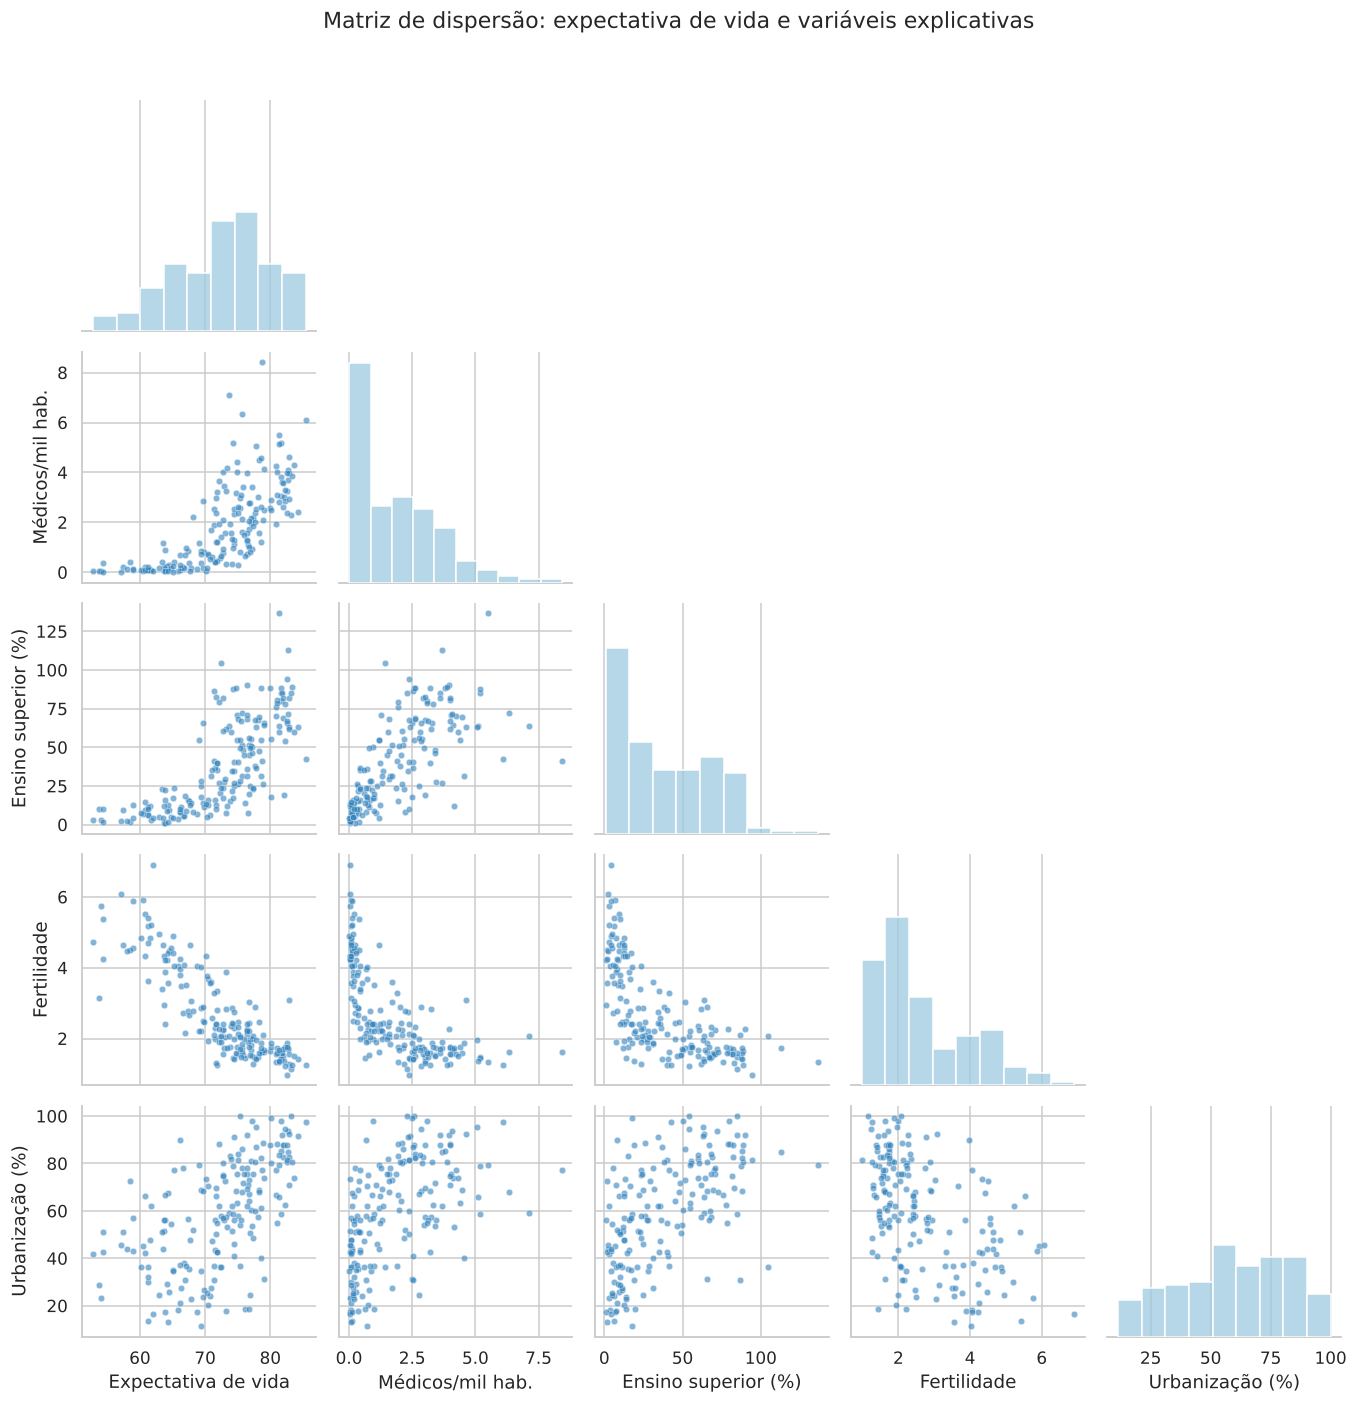


b) Matriz de covariância:
                     Expectativa de vida  Médicos/mil hab.  Ensino superior (%)  Fertilidade  Urbanização (%)
Expectativa de vida                55.62              8.74               159.14        -8.12           100.88
Médicos/mil hab.                    8.74              2.76                34.96        -1.44            20.67
Ensino superior (%)               159.14             34.96               860.91       -25.78           396.81
Fertilidade                        -8.12             -1.44               -25.78         1.64           -15.19
Urbanização (%)                   100.88             20.67               396.81       -15.19           527.35

   Matriz de correlação de Pearson:
                     Expectativa de vida  Médicos/mil hab.  Ensino superior (%)  Fertilidade  Urbanização (%)
Expectativa de vida                1.000             0.705                0.727       -0.851            0.589
Médicos/mil hab.                   0.705             1.0

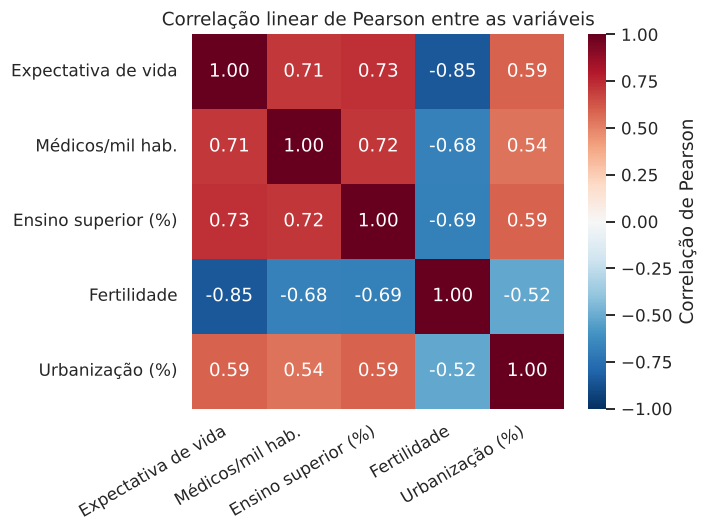


d) Coeficientes estimados:
                     Coeficiente  Erro-padrão        t  p-valor
Intercepto               76.8225       1.4668  52.3727   0.0000
Médicos/mil hab.          0.5407       0.2471   2.1882   0.0300
Ensino superior (%)       0.0405       0.0145   2.7874   0.0059
Fertilidade              -3.4786       0.3065 -11.3502   0.0000
Urbanização (%)           0.0394       0.0146   2.6983   0.0076

   Equação: Expectativa de vida = 76.823 + 0.541×Médicos/mil hab. + 0.041×Ensino superior (%) - 3.479×Fertilidade + 0.039×Urbanização (%)

e) R² = 0.7800 | R² ajustado = 0.7750 | F(4, 177) = 156.87 | p-valor (F) = 4.49e-57
   VIF (multicolinearidade; valores abaixo de 5 são tranquilos): {'Médicos/mil hab.': 2.44, 'Ensino superior (%)': 2.63, 'Fertilidade': 2.22, 'Urbanização (%)': 1.63}


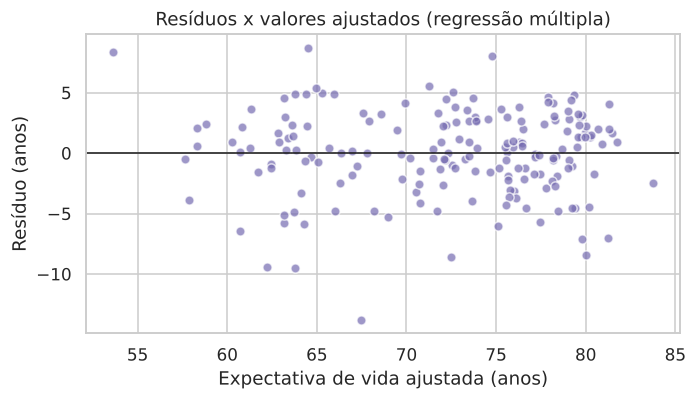


f) Previsão (país hipotético: {'medicos_mil': 2.0, 'ensino_superior': 50.0, 'fertilidade': 2.0, 'urbanizacao': 60.0}): 75.34 anos (intervalo de predição de 95%: 68.3 a 82.3)
   Checagem com o Brasil (médicos 2.15, ensino superior 51.3%, fertilidade 1.73, urbanização 86.2%): previsto = 77.45 anos | observado = 75.7 anos


In [6]:
cols5 = ["expectativa_vida", "medicos_mil", "ensino_superior", "fertilidade", "urbanizacao"]
rot = {"expectativa_vida": "Expectativa de vida", "medicos_mil": "Médicos/mil hab.",
       "ensino_superior": "Ensino superior (%)", "fertilidade": "Fertilidade", "urbanizacao": "Urbanização (%)"}
d5 = df[["pais"] + cols5].dropna().reset_index(drop=True)
print("Observações (países completos):", len(d5))

# a) dispersão (matriz de dispersão)
g = sns.pairplot(d5[cols5].rename(columns=rot), corner=True, plot_kws={"alpha": 0.6, "s": 18, "color": "#3182bd"},
                 diag_kws={"color": "#9ecae1"})
g.figure.suptitle("Matriz de dispersão: expectativa de vida e variáveis explicativas", y=1.02)
salvar("fig05a_dispersao.png")

# b) covariância e correlação
cov5 = d5[cols5].cov(); cor5 = d5[cols5].corr()
print("\nb) Matriz de covariância:"); print(cov5.rename(index=rot, columns=rot).round(2).to_string())
print("\n   Matriz de correlação de Pearson:"); print(cor5.rename(index=rot, columns=rot).round(3).to_string())
for c in cols5[1:]:
    print(f"   Correlação de {rot[c]} com a expectativa de vida: {cor5.loc[c, 'expectativa_vida']:.3f} ({forca(cor5.loc[c, 'expectativa_vida'])})")

# c) gráfico da correlação
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cor5.rename(index=rot, columns=rot), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax,
            cbar_kws={"label": "Correlação de Pearson"})
ax.set_title("Correlação linear de Pearson entre as variáveis")
plt.xticks(rotation=30, ha="right")
salvar("fig05c_correlacao.png")

# d) regressão múltipla
xs5 = cols5[1:]
m5 = ols(d5[xs5].values, d5["expectativa_vida"].values)
tab5 = pd.DataFrame({"Coeficiente": m5["b"], "Erro-padrão": m5["se"], "t": m5["t"], "p-valor": m5["p"]},
                    index=["Intercepto"] + [rot[c] for c in xs5])
print("\nd) Coeficientes estimados:"); print(tab5.round(4).to_string())
eq = f"Expectativa de vida = {m5['b'][0]:.3f}" + "".join(f" {'+' if b >= 0 else '-'} {abs(b):.3f}×{rot[c]}" for b, c in zip(m5["b"][1:], xs5))
print("\n   Equação:", eq)

# e) adequação + multicolinearidade (VIF)
print(f"\ne) R² = {m5['r2']:.4f} | R² ajustado = {m5['r2a']:.4f} | F({m5['k']}, {m5['n']-m5['k']-1}) = {m5['F']:.2f} | p-valor (F) = {m5['pF']:.3g}")
vif = {}
for i, c in enumerate(xs5):
    outros = [o for o in xs5 if o != c]
    r2i = ols(d5[outros].values, d5[c].values)["r2"]
    vif[c] = 1 / (1 - r2i)
print("   VIF (multicolinearidade; valores abaixo de 5 são tranquilos):", {rot[k]: round(v, 2) for k, v in vif.items()})
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.scatter(m5["yhat"], m5["res"], alpha=0.7, color="#756bb1", edgecolor="white")
ax.axhline(0, color="k", lw=1)
ax.set_title("Resíduos x valores ajustados (regressão múltipla)")
ax.set_xlabel("Expectativa de vida ajustada (anos)"); ax.set_ylabel("Resíduo (anos)")
salvar("fig05e_residuos.png")

# f) previsão com 4 variáveis explicativas
def prever(valores):
    v = np.array([1.0] + [valores[c] for c in xs5])
    return float(v @ m5["b"]), float(np.sqrt(m5["s2"] * (1 + v @ m5["XtXi"] @ v)))
novo = {"medicos_mil": 2.0, "ensino_superior": 50.0, "fertilidade": 2.0, "urbanizacao": 60.0}
pn, sepn = prever(novo)
tc5 = stats.t.ppf(0.975, m5["n"] - m5["k"] - 1)
print(f"\nf) Previsão (país hipotético: {novo}): {pn:.2f} anos (intervalo de predição de 95%: {pn - tc5*sepn:.1f} a {pn + tc5*sepn:.1f})")
br = d5[d5["pais"] == "Brazil"].iloc[0]
pbr, sebr = prever({c: br[c] for c in xs5})
print(f"   Checagem com o Brasil (médicos {br['medicos_mil']:.2f}, ensino superior {br['ensino_superior']:.1f}%, fertilidade {br['fertilidade']:.2f}, urbanização {br['urbanizacao']:.1f}%): "
      f"previsto = {pbr:.2f} anos | observado = {br['expectativa_vida']:.1f} anos")

RES["q05"] = {"n": int(len(d5)), "variaveis": [rot[c] for c in xs5],
              "cov": cov5.round(4).values.tolist(), "cor": cor5.round(4).values.tolist(), "ordem_matriz": [rot[c] for c in cols5],
              "coef": [{"nome": n, "b": float(b), "se": float(s), "t": float(t), "p": float(p)}
                       for n, b, s, t, p in zip(tab5.index, m5["b"], m5["se"], m5["t"], m5["p"])],
              "equacao": eq, "r2": m5["r2"], "r2a": m5["r2a"], "F": m5["F"], "pF": m5["pF"],
              "gl1": int(m5["k"]), "gl2": int(m5["n"] - m5["k"] - 1),
              "vif": {rot[k]: float(v) for k, v in vif.items()},
              "novo": novo, "pred_novo": pn, "pred_novo_li": pn - tc5 * sepn, "pred_novo_ls": pn + tc5 * sepn,
              "brasil": {"previsto": pbr, "observado": float(br["expectativa_vida"]),
                         "medicos_mil": float(br["medicos_mil"]), "ensino_superior": float(br["ensino_superior"]),
                         "fertilidade": float(br["fertilidade"]), "urbanizacao": float(br["urbanizacao"])}}

## 6. Regressão logística binária (2,0 pontos)
Variável resposta binária: **expectativa de vida alta** = 1 se a expectativa de vida do país é maior ou igual à mediana da base (países acima da mediana), 0 caso contrário. Variáveis explicativas: médicos por mil habitantes, ensino superior (%), fertilidade e urbanização. Divisão em treino (70%) e teste (30%), estratificada e com semente fixa. O modelo é estimado por máxima verossimilhança (método de Newton-Raphson).

Corte (mediana da expectativa de vida): 73.50 anos | proporção de 'alta': 0.500

Treino: 127 países | Teste: 55 países

a) Coeficientes (modelo estimado no treino):
                     Coeficiente  Erro-padrão       z  p-valor  Razão de chances
Intercepto                0.8460       1.7677  0.4786   0.6322            2.3304
Médicos/mil hab.          0.3833       0.3093  1.2394   0.2152            1.4671
Ensino superior (%)       0.0039       0.0152  0.2568   0.7974            1.0039
Fertilidade              -2.2819       0.6552 -3.4825   0.0005            0.1021
Urbanização (%)           0.0599       0.0184  3.2655   0.0011            1.0618

   Equação: logit(P(alta)) = ln(P/(1-P)) = 0.846 + 0.383×Médicos/mil hab. + 0.004×Ensino superior (%) - 2.282×Fertilidade + 0.060×Urbanização (%)
   P(alta) = 1 / (1 + exp(-logit))
   Pseudo-R² de McFadden = 0.615

b) Matriz de confusão (teste; linhas = real, colunas = previsto):
             Prev: baixa  Prev: alta
Real: baixa           23      

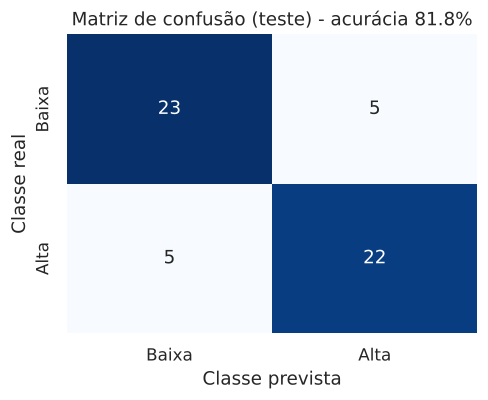


c) Classificações:
   País A (hipotético): {'medicos_mil': 0.5, 'ensino_superior': 10.0, 'fertilidade': 4.5, 'urbanizacao': 35.0} -> P(alta) = 0.001 -> expectativa de vida baixa
   País B (hipotético): {'medicos_mil': 3.0, 'ensino_superior': 65.0, 'fertilidade': 1.6, 'urbanizacao': 80.0} -> P(alta) = 0.968 -> expectativa de vida alta
   Brasil (dados reais): {'medicos_mil': 2.15, 'ensino_superior': 51.3, 'fertilidade': 1.73, 'urbanizacao': 86.20725611041735} -> P(alta) = 0.956 -> expectativa de vida alta
   (Brasil observado: 75.7 anos; corte = 73.50)

Resultados salvos em resultados/resultados.json


In [7]:
corte = d5["expectativa_vida"].median()
d5["alta_exp"] = (d5["expectativa_vida"] >= corte).astype(int)
print(f"Corte (mediana da expectativa de vida): {corte:.2f} anos | proporção de 'alta': {d5['alta_exp'].mean():.3f}")

def logit(X, y, iters=100, tol=1e-10):
    X = np.asarray(X, float); y = np.asarray(y, float)
    Xc = np.column_stack([np.ones(len(y)), X]); b = np.zeros(Xc.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-(Xc @ b))); W = p * (1 - p)
        H = Xc.T @ (Xc * W[:, None]); passo = np.linalg.solve(H, Xc.T @ (y - p)); b = b + passo
        if np.max(np.abs(passo)) < tol: break
    p = 1 / (1 + np.exp(-(Xc @ b))); W = p * (1 - p)
    cov = np.linalg.inv(Xc.T @ (Xc * W[:, None])); se = np.sqrt(np.diag(cov))
    ll = float(np.sum(y * np.log(p) + (1 - y) * np.log(1 - p)))
    p0 = y.mean(); ll0 = float(len(y) * (p0 * np.log(p0) + (1 - p0) * np.log(1 - p0)))
    return {"b": b, "se": se, "z": b / se, "p": 2 * stats.norm.sf(np.abs(b / se)), "mcfadden": 1 - ll / ll0}

def prob(b, X):
    X = np.asarray(X, float)
    if X.ndim == 1: X = X.reshape(1, -1)
    return 1 / (1 + np.exp(-(b[0] + X @ b[1:])))

Xtr, Xte, ytr, yte = train_test_split(d5[xs5].values, d5["alta_exp"].values, test_size=0.3, random_state=42, stratify=d5["alta_exp"].values)
lg = logit(Xtr, ytr)
tab6 = pd.DataFrame({"Coeficiente": lg["b"], "Erro-padrão": lg["se"], "z": lg["z"], "p-valor": lg["p"], "Razão de chances": np.exp(lg["b"])},
                    index=["Intercepto"] + [rot[c] for c in xs5])
print(f"\nTreino: {len(ytr)} países | Teste: {len(yte)} países")
print("\na) Coeficientes (modelo estimado no treino):"); print(tab6.round(4).to_string())
eq6 = "logit(P(alta)) = ln(P/(1-P)) = " + f"{lg['b'][0]:.3f}" + "".join(f" {'+' if b >= 0 else '-'} {abs(b):.3f}×{rot[c]}" for b, c in zip(lg["b"][1:], xs5))
print("\n   Equação:", eq6)
print("   P(alta) = 1 / (1 + exp(-logit))")
print(f"   Pseudo-R² de McFadden = {lg['mcfadden']:.3f}")

# b) matriz de confusão e acurácia (teste)
pte = prob(lg["b"], Xte); yhat_te = (pte >= 0.5).astype(int)
cmx = confusion_matrix(yte, yhat_te, labels=[0, 1]); acc = accuracy_score(yte, yhat_te)
ptr = prob(lg["b"], Xtr); acc_tr = accuracy_score(ytr, (ptr >= 0.5).astype(int))
tn, fp, fn, tp = cmx.ravel()
sens = tp / (tp + fn); espec = tn / (tn + fp); base_maj = max(yte.mean(), 1 - yte.mean())
print("\nb) Matriz de confusão (teste; linhas = real, colunas = previsto):")
print(pd.DataFrame(cmx, index=["Real: baixa", "Real: alta"], columns=["Prev: baixa", "Prev: alta"]).to_string())
print(f"   Acurácia (teste) = {acc:.3f} | acurácia (treino) = {acc_tr:.3f} | sensibilidade = {sens:.3f} | especificidade = {espec:.3f}")
print(f"   Referência: classificar tudo na classe majoritária daria {base_maj:.3f} de acurácia.")

fig, ax = plt.subplots(figsize=(4.6, 3.8))
sns.heatmap(cmx, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Baixa", "Alta"], yticklabels=["Baixa", "Alta"])
ax.set_title(f"Matriz de confusão (teste) - acurácia {acc:.1%}")
ax.set_xlabel("Classe prevista"); ax.set_ylabel("Classe real")
salvar("fig06b_confusao.png")

# c) classificação de novos países (4 variáveis explicativas)
def classificar_pais(valores):
    p = float(prob(lg["b"], np.array([valores[c] for c in xs5]))[0])
    return p, ("alta" if p >= 0.5 else "baixa")
exemplos = {"País A (hipotético)": {"medicos_mil": 0.5, "ensino_superior": 10.0, "fertilidade": 4.5, "urbanizacao": 35.0},
            "País B (hipotético)": {"medicos_mil": 3.0, "ensino_superior": 65.0, "fertilidade": 1.6, "urbanizacao": 80.0},
            "Brasil (dados reais)": {c: float(br[c]) for c in xs5}}
print("\nc) Classificações:")
cls = {}
for nome, v in exemplos.items():
    p, c = classificar_pais(v); cls[nome] = {"valores": v, "prob": p, "classe": c}
    print(f"   {nome}: {v} -> P(alta) = {p:.3f} -> expectativa de vida {c}")
print(f"   (Brasil observado: {br['expectativa_vida']:.1f} anos; corte = {corte:.2f})")

RES["q06"] = {"corte": float(corte), "prop_alta": float(d5["alta_exp"].mean()), "n_treino": int(len(ytr)), "n_teste": int(len(yte)),
              "coef": [{"nome": n, "b": float(b), "se": float(s), "z": float(z), "p": float(p), "or": float(np.exp(b))}
                       for n, b, s, z, p in zip(tab6.index, lg["b"], lg["se"], lg["z"], lg["p"])],
              "equacao": eq6, "mcfadden": lg["mcfadden"], "confusao": cmx.tolist(), "acuracia": float(acc), "acuracia_treino": float(acc_tr),
              "sensibilidade": float(sens), "especificidade": float(espec), "base_majoritaria": float(base_maj), "classificacoes": cls,
              "brasil_observado": float(br["expectativa_vida"])}

with open(os.path.join(DIR_RES, "resultados.json"), "w", encoding="utf-8") as f:
    json.dump(RES, f, ensure_ascii=False, indent=2, default=float)
print("\nResultados salvos em resultados/resultados.json")